In [2]:
from requirements import *
from utils.tl.deg import runDEseq

# Extended Data Figure 5

In [3]:
adata_xenv1 = sc.read_h5ad(XEN_V1)

## ED Figure 5a. Immune aggregate neighborhood enrichment score calculation for PCA


In [6]:
import squidpy as sq

rows = []

for agg in adata_xenv1[adata_xenv1.obs['in_tls'] == 'Yes'].obs['tls'].unique():
    tmp = adata_xenv1[adata_xenv1.obs['neighbor_tls'] == agg]
    size = tmp[tmp.obs['in_tls'] == 'Yes'].shape[0]
    diagnosis = tmp.obs['diagnosis'][0]
    sq.gr.spatial_neighbors(tmp, n_neighs=5)
    sq.gr.nhood_enrichment(tmp, cluster_key="ct_refined")

    ct_order = list(tmp.obs['ct_refined'].cat.categories)
    zscores = tmp.uns['ct_refined_nhood_enrichment']['zscore']
    for ct in ct_order:
        for i, score in enumerate(zscores[ct_order.index(ct)]):
            rows.append({
                'neighbor': ct,
                'enrichment': score,
                'tls': agg,
                'type': diagnosis,
                'from': ct_order[i],
                'size': size,
            })

tls_enrich_df = pd.DataFrame(rows, columns=['neighbor', 'enrichment', 'tls', 'type', 'from', 'size'])

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

... (487 outputs left out)

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 0/1000 [00:00<?, ?/s]

In [7]:
tls_enrich_df

,neighbor,enrichment,tls,type,from,size
0,B Mature,-0.388607,70944_0,MDS-LB,B Mature,65
1,B Mature,1.360925,70944_0,MDS-LB,CD4 Memory,65
2,B Mature,0.689993,70944_0,MDS-LB,CD4 Naive/Central Memory,65
3,B Mature,-0.141456,70944_0,MDS-LB,CD8 Memory,65
4,B Mature,2.440978,70944_0,MDS-LB,CD8 Naive,65
...,...,...,...,...,...,...
87442,Plasma Cell,-0.411657,7052_64,Control-Lymph,Late/Mature Myeloid,15
87443,Plasma Cell,-0.371021,7052_64,Control-Lymph,Megakaryocyte,15
87444,Plasma Cell,-0.338862,7052_64,Control-Lymph,Mesenchymal/Stromal,15
87445,Plasma Cell,-0.465108,7052_64,Control-Lymph,NK,15


## ED Figure 5d. Cytokine clusters in vs out immune aggregates by size

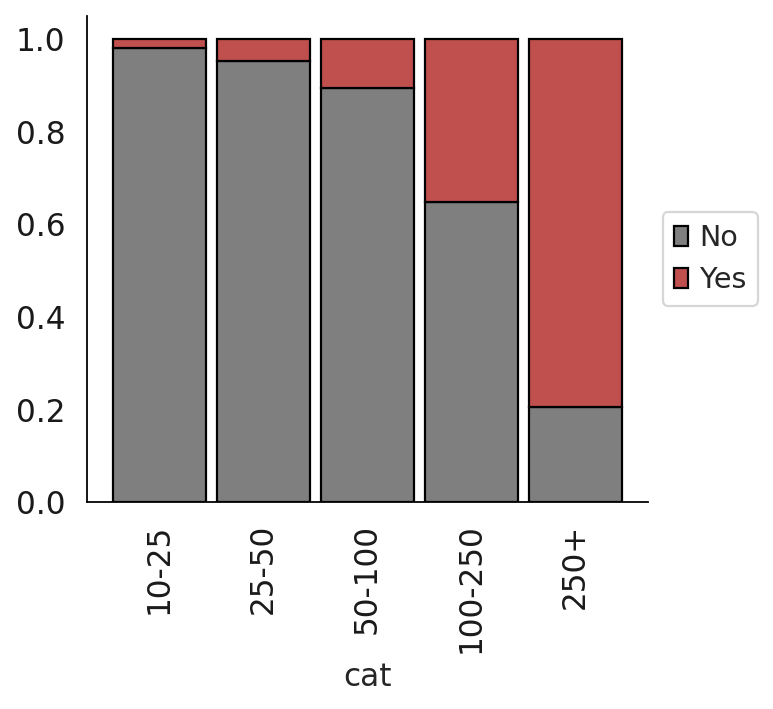

In [4]:
cyto_df = pd.read_csv('/data1/greenbab/users/zhangb2/xenium_files/review_samples/rviz/v1_cytokine_clusters.tsv', index_col=0) # SEE Figure_03.ipynb Fig 3d to generate
tmp = adata_xenv1.obs[adata_xenv1.obs["neighbor_tls"] != 'NA']
di = tmp.groupby("cytokine_cell")["neighbor_tls"].apply(set).to_dict()

cyto_df['tls'] = [','.join(di[x]) if x in di else 'NA' for x in cyto_df.index] 
cyto_df['tls'][cyto_df['tls'] == ''] = 'NA'

cyto_df['cat'] = '10-25'
cyto_df['cat'][cyto_df['size'] > 25] = '25-50'
cyto_df['cat'][cyto_df['size'] > 50] = '50-100'
cyto_df['cat'][cyto_df['size'] > 100] = '100-250'
cyto_df['cat'][cyto_df['size'] > 250] = '250+'

cyto_df['in_tls'] = 'Yes'
cyto_df['in_tls'][cyto_df['tls'] == 'NA'] = 'No'

sc.set_figure_params(figsize=(4.5, 4))

df = pd.crosstab(index=cyto_df['cat'], columns=cyto_df['in_tls']).apply(lambda x: x/x.sum(), axis=1)
df = df.reindex(index = ['10-25', '25-50', '50-100', '100-250', '250+'])

cmp = matplotlib.colors.ListedColormap(["#807F7F", "#BF504D"])

g = df.plot(kind='bar', stacked=True, width = 0.9,colormap= cmp,edgecolor='black')
g.spines['top'].set_visible(False)
g.spines['right'].set_visible(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()

## ED Figure 5e. Cytokine clusters within CD8-memory-rich and CD4-naive/CM-rich aggregates

In [ ]:
### dataframe for immune aggregate composition heatmap
tls = adata_xenv1[adata_xenv1.obs['in_tls'] == 'Yes']
df = pd.crosstab(index=tls.obs['tls'], columns=tls.obs['ct_refined']).apply(lambda x: x/x.sum(), axis=1)
from collections import Counter
tls_sizes = Counter(tls.obs['tls'])
df['Size'] = [tls_sizes[x] for x in df.index]
df['group'] = ['Small' if x < 100 else 'Large' for x in df['Size']]
samptype = dict(zip(tls.obs['tls'], tls.obs['diagnosis']))
df['Diagnosis'] = [samptype[x] for x in df.index]
df['group'] = [df['Diagnosis'][i].split('-')[0] + ' ' + df['group'][i] for i in range(df.shape[0])]


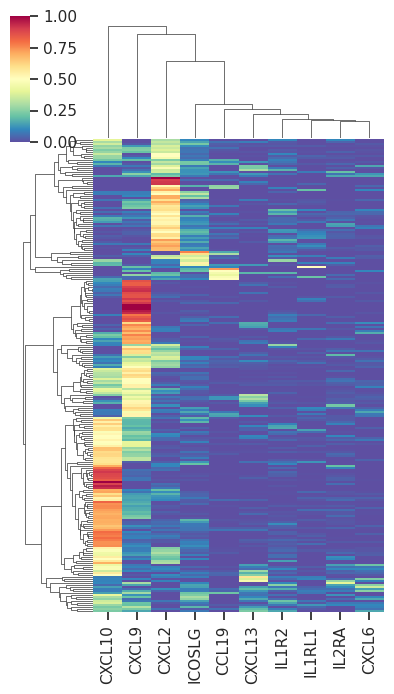

In [5]:
## CD8 Memory-rich aggregates
cyto_df = pd.read_csv('v1_cytokine_clusters.tsv', index_col=0) # SEE Figure_03.ipynb Fig 3d to generate
tmp = adata_xenv1.obs[adata_xenv1.obs["neighbor_tls"] != 'NA']
di = tmp.groupby("neighbor_tls")["cytokine_cell"].apply(set).to_dict()

curr_tls = [x for x in df[df['CD8 Memory'] >= 0.33].index]
curr_clusts = [di[x] for x in curr_tls]
curr_clusts = list(set().union(*curr_clusts))

cyto_df = cyto_df.loc[[x for x in curr_clusts if not x == 'NA'],:]

cyto_df = cyto_df.iloc[:,0:10]
cyto_pct = cyto_df.div(cyto_df.sum(axis=1), axis=0)
sns.set_style("ticks")
g = sns.clustermap(cyto_pct, row_cluster=True, yticklabels=False,  xticklabels=True, cmap = 'Spectral_r', figsize=(4, 7), vmin=0, vmax=1) #row_colors=row_colors,
g.ax_heatmap.tick_params(right=False, bottom=True)
plt.show()


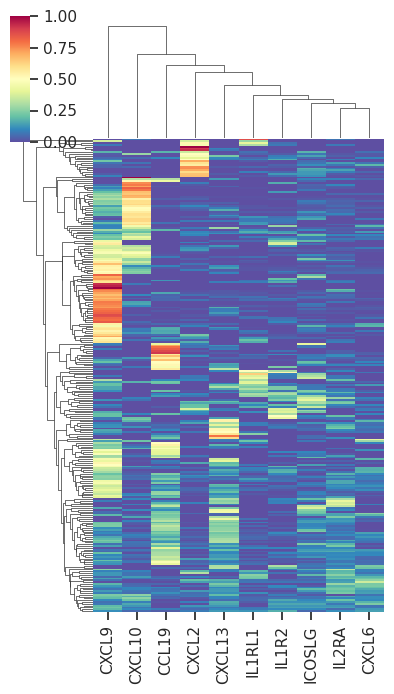

In [6]:
## CD4 Naive/Central Memory-rich aggregates
cyto_df = pd.read_csv('v1_cytokine_clusters.tsv', index_col=0) # SEE Figure_03.ipynb Fig 3d to generate
tmp = adata_xenv1.obs[adata_xenv1.obs["neighbor_tls"] != 'NA']
di = tmp.groupby("neighbor_tls")["cytokine_cell"].apply(set).to_dict()

curr_tls = [x for x in df[df['CD4 Naive/Central Memory'] >= 0.33].index]
curr_clusts = [di[x] for x in curr_tls]
curr_clusts = list(set().union(*curr_clusts))

cyto_df = cyto_df.loc[[x for x in curr_clusts if not x == 'NA'],:]

cyto_df = cyto_df.iloc[:,0:10]
cyto_pct = cyto_df.div(cyto_df.sum(axis=1), axis=0)
g = sns.clustermap(cyto_pct, row_cluster=True, yticklabels=False,  xticklabels=True, cmap = 'Spectral_r', figsize=(4, 7), vmin=0, vmax=1) #row_colors=row_colors,
g.ax_heatmap.tick_params(right=False, bottom=True)

plt.show()


## ED Figure 5i. DEG analysis for volcano plot: Memory T cells near vs far immune aggregates

In [3]:
ad_t = adata_xenv1[adata_xenv1.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
ad_t = ad_t[ad_t.obs['ct_refined'].isin(['CD4 Memory', 'CD8 Memory'])]

t_cell_genes = ['BCL2L11', 'CCL5', 'CCR7', 'CCR8', 'CD2', 'CD244', 'CD247', 'CD27',
                'CD28', 'CD3D', 'CD3E', 'CD4', 'CD5', 'CD69', 'CD7', 'CD8A',
                'CTLA4', 'ENTPD1', 'FAS', 'FOXP3', 'GATA3', 'GNLY', 'GZMA',
                'GZMB', 'GZMK', 'HAVCR2', 'ICOS', 'IKZF2', 'IL2RA', 'IL7R',
                'ITGA6', 'KLRB1', 'KLRC1', 'KLRD1', 'KLRG1', 'LAG3', 'LEF1',
                'NKG7', 'PDCD1', 'PRF1', 'PTPRC', 'SATB2', 'SELL', 'SH2D3C',
                'SLAMF1', 'SPN', 'TBX21', 'TCF7', 'TIGIT', 'TNFRSF9', 'TOX', 'TRAC']

ad_t = ad_t[:, [g for g in t_cell_genes]] # subset to t cell genes

res = runDEseq(
    ad_t, 
    patient_col = 'study_id', 
    condition_col = 'in_tls',
    cond_1 = 'No',
    cond_2 = 'Yes',
    min_cells_per_sample=25)

res = res.sort_values(by='padj')
res

Removing 18 unpaired samples
MDS-9_No      18348
MDS-18_No     12902
MDS-28_No      7069
MDS-19_No      6134
MDS-8_No       6066
MDS-31_No      5186
MDS-11_No      2634
MDS-41_No      2458
MDS-2_No       1919
MDS-35_No      1784
MDS-20_No      1737
MDS-14_No      1699
MDS-24_No      1375
MDS-7_No       1244
MDS-34_No      1047
MDS-1_No        970
MDS-4_No        963
MDS-6_No        959
MDS-9_Yes       925
MDS-36_No       887
MDS-15_No       886
MDS-28_Yes      876
MDS-21_No       756
MDS-30_No       598
MDS-35_Yes      503
MDS-31_Yes      402
MDS-8_Yes       387
MDS-20_Yes      344
MDS-18_Yes      326
MDS-3_No        324
MDS-14_Yes      202
MDS-11_Yes      185
MDS-24_Yes      168
MDS-2_Yes        98
MDS-1_Yes        77
MDS-41_Yes       75
MDS-19_Yes       74
MDS-15_Yes       74
MDS-30_Yes       59
MDS-34_Yes       52
MDS-4_Yes        37
MDS-6_Yes        37
MDS-36_Yes       31
MDS-3_Yes        29
MDS-7_Yes        26
MDS-21_Yes       25
Name: sample_group, dtype: int64

Retaining 46 / 46

Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 1.49 seconds.

Fitting dispersion trend curve...
... done in 0.02 seconds.

Fitting MAP dispersions...
... done in 0.06 seconds.

Fitting LFCs...
... done in 0.04 seconds.

Refitting 0 outliers.

Running Wald tests...
... done in 0.05 seconds.



Log2 fold change & Wald test p-value: in-tls Yes vs No
            baseMean  log2FoldChange     lfcSE      stat        pvalue  \
BCL2L11    60.504888       -0.097718  0.104890 -0.931617  3.515344e-01   
CCL5      901.046629       -0.034092  0.038858 -0.877343  3.803002e-01   
CCR7       36.922632        1.240037  0.152015  8.157359  3.424281e-16   
CCR8        6.522627        0.356410  0.302788  1.177094  2.391582e-01   
CD2       534.694690        0.061716  0.033900  1.820547  6.867570e-02   
CD244     100.201460       -0.559645  0.098893 -5.659099  1.521695e-08   
CD247     284.060575       -0.151061  0.052071 -2.901079  3.718796e-03   
CD27       83.521800        0.351746  0.093428  3.764888  1.666238e-04   
CD28      146.450830        0.251939  0.082007  3.072160  2.125157e-03   
CD3D      359.020090       -0.031531  0.043585 -0.723436  4.694119e-01   
CD3E      548.882896       -0.024528  0.031946 -0.767772  4.426224e-01   
CD4       106.620093        0.362338  0.079301  4.569125 

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
TCF7,212.199857,0.518027,0.064090,8.082773,6.331025e-16,1.646066e-14
CCR7,36.922632,1.240037,0.152015,8.157359,3.424281e-16,1.646066e-14
LEF1,80.357268,0.777396,0.107814,7.210558,5.572309e-13,9.658669e-12
KLRD1,175.568945,-0.566883,0.083743,-6.769278,1.294267e-11,1.682547e-10
GZMA,497.268659,-0.230709,0.037538,-6.146046,7.943817e-10,8.261569e-09
SELL,66.329353,0.851828,0.141055,6.038961,1.551094e-09,1.344281e-08
KLRB1,235.680932,-0.510930,0.085318,-5.988535,2.117402e-09,1.572927e-08
KLRG1,588.849555,-0.267815,0.045481,-5.888483,3.897559e-09,2.533414e-08
PRF1,180.305442,-0.418836,0.072399,-5.785119,7.246102e-09,4.186637e-08
CD244,100.201460,-0.559645,0.098893,-5.659099,1.521695e-08,7.912813e-08
